<img src="https://github.com/milatovicdanka90-maker/DSB-Unit-03/blob/main/labs/01%20-%20Regression-Sacramento/assets/ga-logo.png?raw=1" style="float: left; margin: 20px; height: 55px">

# Lab: Simple Linear Regression with Sacramento Real Estate Data

---

In this lab you will hone your exploratory data analysis (EDA) skills and practice constructing linear regressions on a data set of Sacramento real estate sales.  The data set contains information on qualities of the property, location of the property, and time of sale.

# Author: "Danka Milatovic"

### 1. Read in the Sacramento housing data set.

The file is stored in the `data` subfolder.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.linear_model import LinearRegression, LassoCV, RidgeCV
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error, mean_absolute_error

In [2]:
sacr = pd.read_csv('https://raw.githubusercontent.com/milatovicdanka90-maker/DSB-Unit-03/refs/heads/main/labs/01%20-%20Regression-Sacramento/data/sacramento_real_estate_transactions.csv')

In [3]:
sacr.head(10)

,street,city,zip,state,beds,baths,sq__ft,type,sale_date,price,latitude,longitude
0,3526 HIGH ST,SACRAMENTO,95838,CA,2,1,836,Residential,Wed May 21 00:00:00 EDT 2008,59222,38.631913,-121.434879
1,51 OMAHA CT,SACRAMENTO,95823,CA,3,1,1167,Residential,Wed May 21 00:00:00 EDT 2008,68212,38.478902,-121.431028
2,2796 BRANCH ST,SACRAMENTO,95815,CA,2,1,796,Residential,Wed May 21 00:00:00 EDT 2008,68880,38.618305,-121.443839
3,2805 JANETTE WAY,SACRAMENTO,95815,CA,2,1,852,Residential,Wed May 21 00:00:00 EDT 2008,69307,38.616835,-121.439146
4,6001 MCMAHON DR,SACRAMENTO,95824,CA,2,1,797,Residential,Wed May 21 00:00:00 EDT 2008,81900,38.519470,-121.435768
5,5828 PEPPERMILL CT,SACRAMENTO,95841,CA,3,1,1122,Condo,Wed May 21 00:00:00 EDT 2008,89921,38.662595,-121.327813
6,6048 OGDEN NASH WAY,SACRAMENTO,95842,CA,3,2,1104,Residential,Wed May 21 00:00:00 EDT 2008,90895,38.681659,-121.351705
7,2561 19TH AVE,SACRAMENTO,95820,CA,3,1,1177,Residential,Wed May 21 00:00:00 EDT 2008,91002,38.535092,-121.481367
8,11150 TRINITY RIVER DR Unit 114,RANCHO CORDOVA,95670,CA,2,2,941,Condo,Wed May 21 00:00:00 EDT 2008,94905,38.621188,-121.270555
9,7325 10TH ST,RIO LINDA,95673,CA,3,2,1146,Residential,Wed May 21 00:00:00 EDT 2008,98937,38.700909,-121.442979


In [4]:
sacr.tail(10)

,street,city,zip,state,beds,baths,sq__ft,type,sale_date,price,latitude,longitude
975,5024 CHAMBERLIN CIR,ELK GROVE,95757,CA,3,2,1450,Residential,Thu May 15 00:00:00 EDT 2008,228000,38.389756,-121.446246
976,2400 INVERNESS DR,LINCOLN,95648,CA,3,2,1358,Residential,Thu May 15 00:00:00 EDT 2008,229027,38.897814,-121.324691
977,5 BISHOPGATE CT,SACRAMENTO,95823,CA,4,2,1329,Residential,Thu May 15 00:00:00 EDT 2008,229500,38.467936,-121.445477
978,5601 REXLEIGH DR,SACRAMENTO,95823,CA,4,2,1715,Residential,Thu May 15 00:00:00 EDT 2008,230000,38.445342,-121.441504
979,1909 YARNELL WAY,ELK GROVE,95758,CA,3,2,1262,Residential,Thu May 15 00:00:00 EDT 2008,230000,38.417382,-121.484325
980,9169 GARLINGTON CT,SACRAMENTO,95829,CA,4,3,2280,Residential,Thu May 15 00:00:00 EDT 2008,232425,38.457679,-121.359620
981,6932 RUSKUT WAY,SACRAMENTO,95823,CA,3,2,1477,Residential,Thu May 15 00:00:00 EDT 2008,234000,38.499893,-121.458890
982,7933 DAFFODIL WAY,CITRUS HEIGHTS,95610,CA,3,2,1216,Residential,Thu May 15 00:00:00 EDT 2008,235000,38.708824,-121.256803
983,8304 RED FOX WAY,ELK GROVE,95758,CA,4,2,1685,Residential,Thu May 15 00:00:00 EDT 2008,235301,38.417000,-121.397424
984,3882 YELLOWSTONE LN,EL DORADO HILLS,95762,CA,3,2,1362,Residential,Thu May 15 00:00:00 EDT 2008,235738,38.655245,-121.075915


In [5]:
sacr.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 985 entries, 0 to 984
Data columns (total 12 columns):
 #   Column     Non-Null Count  Dtype  
---  ------     --------------  -----  
 0   street     985 non-null    object 
 1   city       985 non-null    object 
 2   zip        985 non-null    int64  
 3   state      985 non-null    object 
 4   beds       985 non-null    int64  
 5   baths      985 non-null    int64  
 6   sq__ft     985 non-null    int64  
 7   type       985 non-null    object 
 8   sale_date  985 non-null    object 
 9   price      985 non-null    int64  
 10  latitude   985 non-null    float64
 11  longitude  985 non-null    float64
dtypes: float64(2), int64(5), object(5)
memory usage: 92.5+ KB


In [6]:
sacr.describe()

,zip,beds,baths,sq__ft,price,latitude,longitude
count,985.000000,985.000000,985.000000,985.000000,985.000000,985.000000,985.000000
mean,95750.697462,2.911675,1.776650,1312.918782,233715.951269,38.445121,-121.193371
std,85.176072,1.307932,0.895371,856.123224,139088.818896,5.103637,5.100670
min,95603.000000,0.000000,0.000000,-984.000000,-210944.000000,-121.503471,-121.551704
25%,95660.000000,2.000000,1.000000,950.000000,145000.000000,38.482704,-121.446119
50%,95762.000000,3.000000,2.000000,1304.000000,213750.000000,38.625932,-121.375799
75%,95828.000000,4.000000,2.000000,1718.000000,300000.000000,38.695589,-121.294893
max,95864.000000,8.000000,5.000000,5822.000000,884790.000000,39.020808,38.668433


### 2. Conduct exploratory data analysis on this data set.

If you discover any issues with the data, fix them to the best of your ability. Report any notable findings.

_**Note:** Zip codes often have leading zeros — e.g., 02215 = Boston, MA — which will often get knocked off automatically by many software programs like Python or Excel._

In [7]:
sacr['state'].unique()

array(['CA', 'AC'], dtype=object)

In [8]:
# I want to remove negative values. I identified that the state AC is the one that has the negative price
# That is why I remove that one
sacr = sacr[sacr['state']!='AC']

<Axes: >

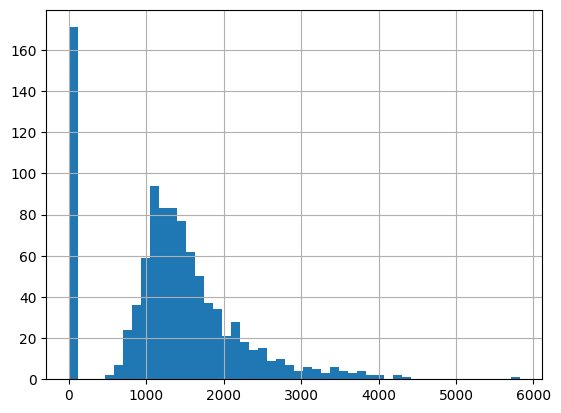

In [9]:
sacr['sq__ft'].hist(bins=50)

In [10]:
sacr = sacr[sacr['sq__ft']>1]

In [11]:
sacr = sacr[sacr['sq__ft']<58000]

In [12]:
sacr.info()

<class 'pandas.core.frame.DataFrame'>
Index: 813 entries, 0 to 984
Data columns (total 12 columns):
 #   Column     Non-Null Count  Dtype  
---  ------     --------------  -----  
 0   street     813 non-null    object 
 1   city       813 non-null    object 
 2   zip        813 non-null    int64  
 3   state      813 non-null    object 
 4   beds       813 non-null    int64  
 5   baths      813 non-null    int64  
 6   sq__ft     813 non-null    int64  
 7   type       813 non-null    object 
 8   sale_date  813 non-null    object 
 9   price      813 non-null    int64  
 10  latitude   813 non-null    float64
 11  longitude  813 non-null    float64
dtypes: float64(2), int64(5), object(5)
memory usage: 82.6+ KB


<Axes: >

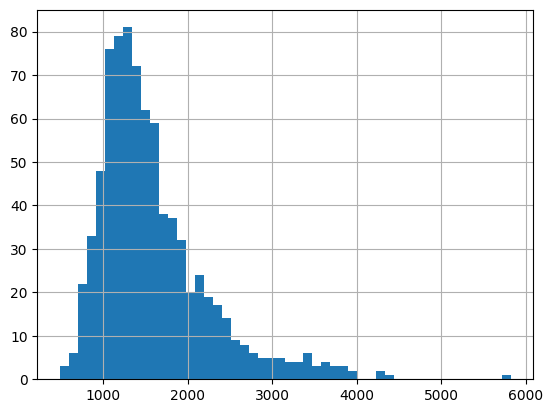

In [13]:
sacr['sq__ft'].hist(bins=50)

In [14]:
sacr.describe()

,zip,beds,baths,sq__ft,price,latitude,longitude
count,813.000000,813.000000,813.000000,813.000000,813.000000,813.000000,813.000000
mean,95761.400984,3.247232,1.961870,1591.892989,229471.130381,38.576931,-121.378533
std,85.357516,0.849012,0.669367,663.908347,119897.576889,0.126352,0.119730
min,95603.000000,1.000000,1.000000,484.000000,2000.000000,38.241514,-121.550527
25%,95670.000000,3.000000,2.000000,1144.000000,148750.000000,38.473814,-121.451444
50%,95820.000000,3.000000,2.000000,1419.000000,207973.000000,38.591618,-121.404999
75%,95828.000000,4.000000,2.000000,1851.000000,285000.000000,38.674864,-121.325730
max,95864.000000,8.000000,5.000000,5822.000000,884790.000000,39.008159,-120.597599


When you've finished cleaning or have made a good deal of progress cleaning, it's always a good idea to save your work. Use the pandas `to_csv` method to export your cleaned dataset.

```python
# example -- your dataframe name may be different
dataframe.to_csv('./datasets/sacramento_cleaned_dataframe.csv', index=False)

```

In [15]:
sacr.to_csv('Sacramento_cleaned_data.csv', index=False)

# Single Linear Regression Model (SLR)

### 3. Our goal will be to predict price. List variables that you think qualify as predictors of price in an SLR model.

For each of the variables you believe should be considered, generate a plot showing the relationship between the independent and dependent variables.

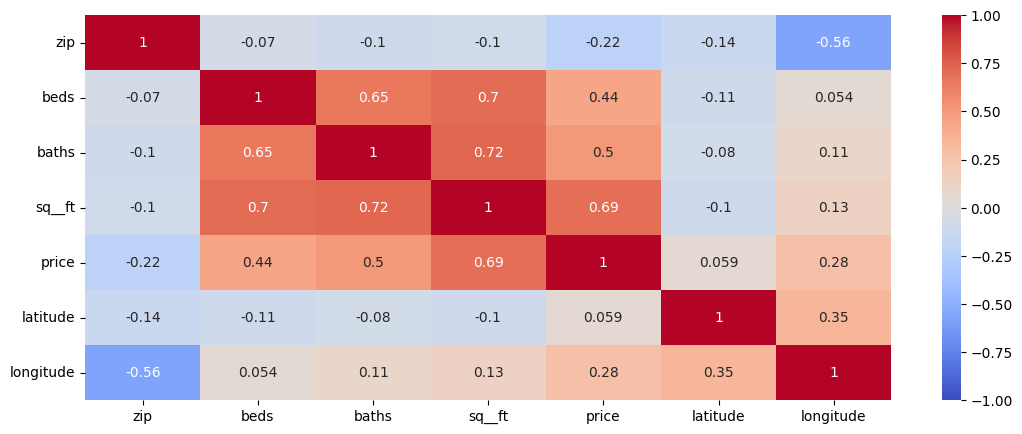

In [16]:
ax, fig = plt.subplots(figsize=(13,5))
sns.heatmap(sacr.corr(numeric_only=True),
            annot=True,
            vmin=-1,
            vmax=1,
            cmap='coolwarm');

### 4. Which variable would be the best predictor of Y in an SLR model? Why?

In [17]:
# I am going to use sq__ft because they have the largest corelation with the price
X = sacr[["sq__ft"]]

In [18]:
y = sacr["price"]

In [19]:
X.shape

(813, 1)

In [20]:
y.shape

(813,)

### 5. Using `scikit-learn` create a SLR and return the intercept and slope coefficients that minimize SSE.

#### SSE (Sum of Squared Errors)

SSE is just the total of all the squared prediction mistakes.

1. For each data point, figure out how far off your prediction was (actual minus predicted).
2. Square that number (to make negatives positive and punish big errors more).
3. Add them all up.

**Why it matters:** You were asked to find the slope and intercept that **minimize SSE**. That's literally what linear regression does — it searches for the line that makes this total as small as possible.

**Related terms:**
- **MSE** = SSE ÷ n (average of the squared errors)
- **RMSE** = √MSE (puts it back in original units)

So: **SSE → MSE → RMSE** is just the same number, adjusted differently for interpretation purposes.


-----

You may need to load in the scikit-learn API:

```python
from sklearn.linear_model import LinearRegression

model = LinearRegression()
```



In [21]:
from sklearn.linear_model import LinearRegression

model = LinearRegression()

In [22]:
lr = LinearRegression()

In [23]:
lr.fit(X, y)

LinearRegression()

### 5 [bonus]. Write a function that will take in two lists, `x` and `y`, and return the intercept and slope coefficients that minimize SSE.

`y` is the target variable, and `x` is the predictor variable.

**Don't use `scikit-learn` for this**. Instead, use `numpy` and `scipy`.

The slope and intercept of simple linear regression can be calculated by using certain summary statistics. In particular, we'll need to know:

- $\bar{x}$, the mean of `x`
- $\bar{y}$, the mean of `y`
- $s_{x}$, the standard deviation of `x`
- $s_{y}$, the standard deviation of `y`
- $r_{xy}$, the correlation of `x` and `y`

Given these summary statistics, the **coefficient on `X`** (or the slope) can be given by $\beta_{1} = r_{xy} * \frac{s_{y}}{s_{x}}$. The **intercept of the model** can be given by $\beta_{0} = \bar{y} - \beta_{1}\bar{x}$.

Your function should take in `x` and `y`, then use the above summary statistics to calculate the slope and intercept.

- **Test your function on price and the variable you determined was the best predictor in Problem 4.**
- **Report the slope and intercept.**

### 6. Interpret the intercept and the slope.

In your own words, write here what is the meaning of each one of those values
and how can they be helpful for you when predicting prices or interpreting the
predictions of your model.

### 7. Give an example of how this model could be used for prediction and how it could be used for inference.

**Be sure to make it clear which example is associated with prediction and which is associated with inference.**

### 8: [Bonus] Using the model you came up with in Part 5, calculate and plot the residuals.

---

## Reminder about categorical variables and dummy variables

It is important to be cautious with categorical variables, which represent distict groups or categories, when building a regression. If put in a regression "as-is," categorical variables represented as integers will be treated like *continuous* variables.

That is to say, instead of group "3" having a different effect on the estimation than group "1" it will estimate literally 3 times more than group 1.

For example, if occupation category "1" represents "analyst" and occupation category "3" represents "barista", and our target variable is salary, if we leave this as a column of integers then barista will always have `beta*3` the effect of analyst.

This will almost certainly force the beta coefficient to be something strange and incorrect. Instead, we can re-represent the categories as multiple "dummy coded" columns.



#### A Word of Caution When Creating Dummies

Let's touch on precautions we should take when dummy coding.

**If you convert a qualitative variable to dummy variables, you want to turn a variable with N categories into N-1 variables.**

> **Scenario 1:** Suppose we're working with the variable "sex" or "gender" with values "M" and "F".

You should include in your model only one variable for "sex = F" which takes on 1 if sex is female and 0 if sex is not female! Rather than saying "a one unit change in X," the coefficient associated with "sex = F" is interpreted as the average change in Y when sex = F relative to when sex = M.

| Female | Male |
|-------|------|
| 0 | 1 |
| 1 | 0 |
| 0 | 1 |
| 1 | 0 |
| 1 | 0 |
_As we can see a 1 in the female column indicates a 0 in the male column. And so, we have two columns stating the same information in different ways._

> Scenario 2: Suppose we're modeling revenue at a bar for each of the days of the week. We have a column with strings identifying which day of the week this observation occured in.

We might include six of the days as their own variables: "Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday". **But not all 7 days.**  

|Monday | Tuesday | Wednesday | Thursday | Friday | Saturday |
|-------|---------|-----------|----------|--------|----------|
| 1     | 0       |0          |      0   |0       | 0        |
| 0     | 1       |0          |      0   |0       | 0        |
| 0     | 0       |1          |      0   |0       | 0        |
| 0     | 0       |0          |      1   |0       | 0        |
| 0     | 0       |0          |      0   |1       | 0        |
| 0     | 0       |0          |      0   |0       | 1        |
| 0     | 0       |0          |      0   |0       | 0        |

_As humans we can infer from the last row that if its is not Monday, Tuesday, Wednesday, Thursday, Friday or Saturday, it must be Sunday. Models work the same way._

The coefficient for Monday is then interpreted as the average change in revenue when "day = Monday" relative to "day = Sunday." The coefficient for Tuesday is interpreted as the average change in revenue when "day = Tuesday" relative to "day = Sunday" and so on.

The category you leave out, which the other columns are *relative to*, is often referred to as the **reference category**.

### 9. Use the `pd.get_dummies` function to convert the `type` column into dummy-coded variables.

In [24]:
sacr.info()

<class 'pandas.core.frame.DataFrame'>
Index: 813 entries, 0 to 984
Data columns (total 12 columns):
 #   Column     Non-Null Count  Dtype  
---  ------     --------------  -----  
 0   street     813 non-null    object 
 1   city       813 non-null    object 
 2   zip        813 non-null    int64  
 3   state      813 non-null    object 
 4   beds       813 non-null    int64  
 5   baths      813 non-null    int64  
 6   sq__ft     813 non-null    int64  
 7   type       813 non-null    object 
 8   sale_date  813 non-null    object 
 9   price      813 non-null    int64  
 10  latitude   813 non-null    float64
 11  longitude  813 non-null    float64
dtypes: float64(2), int64(5), object(5)
memory usage: 82.6+ KB


In [36]:
sacr_dummies = pd.get_dummies(sacr, prefix=None, prefix_sep='', dummy_na=False, columns=['type'], drop_first=False, dtype=None)
sacr_dummies.info()

<class 'pandas.core.frame.DataFrame'>
Index: 813 entries, 0 to 984
Data columns (total 14 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   street            813 non-null    object 
 1   city              813 non-null    object 
 2   zip               813 non-null    int64  
 3   state             813 non-null    object 
 4   beds              813 non-null    int64  
 5   baths             813 non-null    int64  
 6   sq__ft            813 non-null    int64  
 7   sale_date         813 non-null    object 
 8   price             813 non-null    int64  
 9   latitude          813 non-null    float64
 10  longitude         813 non-null    float64
 11  typeCondo         813 non-null    bool   
 12  typeMulti-Family  813 non-null    bool   
 13  typeResidential   813 non-null    bool   
dtypes: bool(3), float64(2), int64(5), object(4)
memory usage: 110.9+ KB


In [37]:
sacr.info()

<class 'pandas.core.frame.DataFrame'>
Index: 813 entries, 0 to 984
Data columns (total 12 columns):
 #   Column     Non-Null Count  Dtype  
---  ------     --------------  -----  
 0   street     813 non-null    object 
 1   city       813 non-null    object 
 2   zip        813 non-null    int64  
 3   state      813 non-null    object 
 4   beds       813 non-null    int64  
 5   baths      813 non-null    int64  
 6   sq__ft     813 non-null    int64  
 7   type       813 non-null    object 
 8   sale_date  813 non-null    object 
 9   price      813 non-null    int64  
 10  latitude   813 non-null    float64
 11  longitude  813 non-null    float64
dtypes: float64(2), int64(5), object(5)
memory usage: 114.9+ KB


In [27]:
#This line is only for me to see the prediction
y_pred = lr.predict(X)

In [29]:
y_pred.round(3)

array([134747.018, 176226.013, 129734.451, 136752.045, 129859.765,
       170586.875, 168331.219, 177479.155, 147905.008, 173594.415,
       143894.954, 191514.343, 139133.015, 157804.828, 158055.456,
       172090.645, 135749.532, 129609.137, 103669.101, 199910.393,
       170085.618, 196526.91 , 185373.948, 230612.368, 142892.44 ,
       166326.192, 150661.92 , 170210.932, 202917.934, 186376.462,
       160185.797, 174346.3  , 202917.934, 169834.989, 160185.797,
       207679.873, 165574.307, 214446.838, 173594.415, 125223.14 ,
       193394.056, 181238.58 , 162316.139, 160687.054, 228857.969,
       170336.246, 227980.77 , 274973.589, 237504.648, 215073.409,
       178857.611, 229233.912, 213319.011, 244772.871, 178481.668,
       206176.102, 273469.818, 176852.584, 174346.3  , 261940.914,
       182241.094, 171589.388, 230862.996, 215324.038, 207930.501,
       190386.515, 228732.655, 200662.278, 300913.624, 188632.117,
       244898.185, 258056.174, 147278.437, 219334.092, 229233.

### 10. Check the dummy columns you've created. Do they all make sense?

Use `.head()` on the new dataframe you've created. Depending on how you cleaned the data earlier in this notebook, there may be a dummy column that needs to be removed. Check that all the columns you've created make sense, and if any of the columns seem to be errors, drop them. If there don't appear to be any errors, then move on to the next step!

In [38]:
sacr_dummies.head(10)

,street,city,zip,state,beds,baths,sq__ft,sale_date,price,latitude,longitude,typeCondo,typeMulti-Family,typeResidential
0,3526 HIGH ST,SACRAMENTO,95838,CA,2,1,836,Wed May 21 00:00:00 EDT 2008,59222,38.631913,-121.434879,False,False,True
1,51 OMAHA CT,SACRAMENTO,95823,CA,3,1,1167,Wed May 21 00:00:00 EDT 2008,68212,38.478902,-121.431028,False,False,True
2,2796 BRANCH ST,SACRAMENTO,95815,CA,2,1,796,Wed May 21 00:00:00 EDT 2008,68880,38.618305,-121.443839,False,False,True
3,2805 JANETTE WAY,SACRAMENTO,95815,CA,2,1,852,Wed May 21 00:00:00 EDT 2008,69307,38.616835,-121.439146,False,False,True
4,6001 MCMAHON DR,SACRAMENTO,95824,CA,2,1,797,Wed May 21 00:00:00 EDT 2008,81900,38.519470,-121.435768,False,False,True
5,5828 PEPPERMILL CT,SACRAMENTO,95841,CA,3,1,1122,Wed May 21 00:00:00 EDT 2008,89921,38.662595,-121.327813,True,False,False
6,6048 OGDEN NASH WAY,SACRAMENTO,95842,CA,3,2,1104,Wed May 21 00:00:00 EDT 2008,90895,38.681659,-121.351705,False,False,True
7,2561 19TH AVE,SACRAMENTO,95820,CA,3,1,1177,Wed May 21 00:00:00 EDT 2008,91002,38.535092,-121.481367,False,False,True
8,11150 TRINITY RIVER DR Unit 114,RANCHO CORDOVA,95670,CA,2,2,941,Wed May 21 00:00:00 EDT 2008,94905,38.621188,-121.270555,True,False,False
9,7325 10TH ST,RIO LINDA,95673,CA,3,2,1146,Wed May 21 00:00:00 EDT 2008,98937,38.700909,-121.442979,False,False,True


# Multivariate Linear Regression Model (MLR)

### 11. Build what you think may be the best MLR model predicting `price`.

Choose at least three variables, and build a model that uses them to predict price. At least one of the variables you choose should be a dummy-coded variable. (This can be one we created before or a new one.)

You may need to load in the scikit-learn API:

```python
from sklearn.linear_model import LinearRegression

model = LinearRegression()
```

In [39]:
from sklearn.linear_model import LinearRegression

model = LinearRegression()

In [41]:
X = sacr_dummies[["sq__ft", "typeCondo", "typeMulti-Family", "typeResidential"]]

In [42]:
X.shape

(813, 4)

In [48]:
y = ['price']

In [50]:
y_pred = lr.predict(X)

In [51]:
y_pred.round(3)

array([137316.042, 178617.199, 132324.966, 139312.473, 132449.743,
       150367.015, 170756.254, 179864.968, 127782.395, 175996.884,
       146424.757, 193839.982, 141683.234, 160274.993, 160524.547,
       151864.338, 138314.257, 109564.966, 106371.369, 202200.035,
       172503.131, 198831.058, 187725.913, 232770.378, 145426.541,
       168759.823, 153162.71 , 172627.907, 205194.681, 188724.129,
       140010.532, 176745.545, 205194.681, 172253.577, 140010.532,
       209936.203, 168011.162, 216674.156, 175996.884, 105197.774,
       173076.413, 183608.275, 164766.962, 163144.862, 231023.501,
       172752.684, 230150.063, 276941.403, 239633.108, 217298.041,
       181237.514, 231397.832, 215551.164, 246870.168, 180863.183,
       208438.88 , 211567.492, 179241.084, 176745.545, 263964.605,
       184606.491, 174000.453, 233019.931, 217547.595, 210185.757,
       192716.99 , 230898.724, 202948.696, 238893.635, 190970.113,
       246994.945, 260096.521, 149793.733, 221540.456, 231397.

### 12. Plot the true price vs the predicted price to evaluate your MLR visually.

You can use matplotlib or seaborn, the choice is yours !

### 13. List the five assumptions for an MLR model.

Indicate which ones are the same as the assumptions for an SLR model.

In [25]:
# convert this cell to markdown to provide your answer

### 14. Pick at least two assumptions and explain whether or not you believe them to be met for your model, and explain why.

### 15. [Bonus - optional] Generate a table showing the point estimates, standard errors, t-scores, p-values, and 95% confidence intervals for the model you built.

**Write a few sentences interpreting some of the output.**

> **Hint:** scikit-learn does not have this functionality built in, but statsmodels does in the `summary` method.  To fit the statsmodels model use something like the following.  There is one big caveat here, however!  `statsmodels.OLS` does _not_ add an intercept to your model, so you will need to do this explicitly by adding a column filled with the number 1 to your X matrix

```python
import statsmodels.api as sm

# The Default here is Linear Regression (ordinary least squares regression OLS)
model = sm.OLS(y,X).fit()
```

### 16. Metrics, metrics, everywhere...

Calculate and interpret at least three regression metrics. How well does your model perform?

## Metric Comparison Table

| Metric | What It Tells You | Punishes Big Mistakes? | Adjusts for Extra Inputs? | Examples of When to Use It |
|---|---|---|---|---|
| **R²** | What percent of the output's variation did the model explain? (0% to 100%) | Indirectly | ❌ No | • Pitching model quality in a presentation: "My model explains 73% of the price variation."<br>• Comparing two models on the same dataset.<br>• Quick sanity check: if R² is near zero, your inputs aren't helping. |
| **Adjusted R²** | Like R², but penalizes you for throwing in too many inputs | Indirectly | ✅ Yes | • You add/remove variables and want to know if performance truly improved.<br>• Deciding whether a new feature is worth keeping in production.<br>• Anytime you're comparing models with different numbers of predictors. |
| **MSE** | Average squared error. Lower is better. | ✅ Strongly (squared!) | ❌ No | • The loss function that regression algorithms optimize internally.<br>• Math-heavy contexts (calculus, derivation).<br>• Rarely reported to stakeholders — too abstract. |
| **RMSE** | On average, how far off are predictions (in original units)? | ✅ Strongly | ❌ No | • "Predictions are off by ~$45,000 on average."<br>• Reporting to non-technical audiences who want dollar amounts.<br>• When large outliers matter and you want to catch them. |
| **MAE** | On average, how far off are predictions (in original units)? | ❌ Mildly (linear) | ❌ No | • When outliers are noisy measurements you don't want to overweight.<br>• Plain-language explanations: "Typical error is about $40,000."<br>• When you want a robust, easy-to-grasp error measure. |

---

## Which Metrics to Report?

**Quick analogy:** If you're reporting to your professor, think of it like grading on multiple axes:
- **R²** answers: "How much of the puzzle did you solve?"
- **RMSE/MAE** answer: "By how many points, on average, were your answers wrong?"
- **Adjusted R²** answers: "Did you actually improve, or just throw more pages at the problem?"

### 16. [Bonus - Optional] Regression Metrics

Implement a function called `r2_adj()` that will calculate $R^2_{adj}$ for a model.

### 18. Model Iteration

Adjust your model by adding or removing a variable. Then calculate the same regression metrics as you used in question 17. Has your model performance increased or decreased?

### 19. Bias vs. Variance

At this point, do you think your model is high bias, high variance or in the
sweet spot?

Hint: cross validation, test ... !